# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


from sklearn.tree import DecisionTreeClassifier 
from sklearn.model_selection import train_test_split 
from sklearn import metrics 
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn import svm
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import time
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data/zadanie-1/pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

## Loading datasets 

In [3]:
data_train = pd.read_csv("data/zadanie-1/pendigits/pendigits.tra", header = None)
data_test = pd.read_csv("data/zadanie-1/pendigits/pendigits.tes", header = None)

First we need to check if there are any missing records. The 'pendigits-orig.tra'contains 7494 training records and 'pendigits-orig.tes' contains 3498 testing records

In [4]:
print(f"Shape of training dataset : {data_train.shape}")
print(f"Shape of testing dataset :  {data_test.shape}")

Shape of training dataset : (7494, 17)
Shape of testing dataset :  (3498, 17)


There are no missing records in dataset 

#### Checking for missing values in dataset

In [5]:
print(data_train.isna().sum().sum())
print(data_test.isna().sum().sum())

0
0


There are no missing values in our dataset

## Splitting training dataset into 3 parts 

In [6]:
actual_training_set = data_train.iloc[:3748] # data for learning process
validation_set = data_train.iloc[3748: (1873 + 3748)] # on this dataset I will compare different models accuracy 
writer_dependent_test = data_train.iloc[(1873 + 3748):] # this dataset is for checking how best performing model is accurate with unseen data

## Extracting a feature vector and a label vector from each subset

In [7]:
# The feature vector consists of 8 points in a Cartesian coordinate system with values ranging from 0–100 
# The label vector is a digit from 0–9 written by the author
X_train = actual_training_set.iloc[:,0:16] # feature matrix
y_train = actual_training_set.iloc[:,16] # label vector

X_val = validation_set.iloc[:,0:16]
y_val = validation_set.iloc[:,16] 

X_wdt = writer_dependent_test.iloc[:,0:16]
y_wdt = writer_dependent_test.iloc[:,16]

X_test = data_test.iloc[:,0:16]
y_test = data_test.iloc[:,16]

### Checking if the classes are balanced


In [8]:
print(y_train.value_counts().sort_index().rename_axis(None))

min_samples = y_train.value_counts().min()
max_samples = y_train.value_counts().max()
print("Biggest difference: ", max_samples - min_samples)

0    384
1    390
2    392
3    370
4    391
5    375
6    351
7    375
8    363
9    357
Name: count, dtype: int64
Biggest difference:  41


We can see that all 10 classes ale balanced. In this dataset that difference in number of samples (41) can be neglected and we can assume that our dataset is perfectly balanced. That means we will choose which model is best based on their accuracy score on validation dataset

## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

## Initializing Baseline Model 

In [9]:
# Initializing model
dummy_clf = DummyClassifier(strategy = "most_frequent")

# Measuring learning time 
start_train_dummy = time.perf_counter()
dummy_clf.fit(X_train, y_train)
end_train_dummy = time.perf_counter()
print(f"(Baseline model) Dummy Classifier's learning time: {end_train_dummy - start_train_dummy:.5f}s")


# Calculating accuracy
y_pred_dummy = dummy_clf.predict(X_val)
print("(Baseline model) Dummy Classifier's accuracy:", round(metrics.accuracy_score(y_val, y_pred_dummy),4))


(Baseline model) Dummy Classifier's learning time: 0.01798s
(Baseline model) Dummy Classifier's accuracy: 0.1073


# The process of modeling will include initializing and tuning 5 classifiers. Those 5 classsifiers are :
1) Decision Tree
2) Random Forest
3) Support Vector Machine (SVM)
4) K-Nearest Neighbors(k-NN)
5) Gaussian Naive Bayes


## 1.1) Decision Tree (Untuned Model)

In [10]:
# Initializing model
clf_tree = DecisionTreeClassifier(random_state = 42)


# Measuring learning time 
start_train_tree_u = time.perf_counter()
clf_tree = clf_tree.fit(X_train, y_train)
end_train_tree_u = time.perf_counter()
print(f"(Untuned) Decision Tree's learning time : {end_train_tree_u - start_train_tree_u:.5f}s")


# Calculating accuracy
y_pred_no_param_dt = clf_tree.predict(X_val)
print("(Untuned) Decision Tree's accuracy :", round(metrics.accuracy_score(y_val,y_pred_no_param_dt),4))

(Untuned) Decision Tree's learning time : 0.05960s
(Untuned) Decision Tree's accuracy : 0.9375


## 1.2) Decision Tree (Optimized Model)

In [11]:
# Searching for the best hyperparameters 
grid_param_dt = {
    'max_depth' : [16,17,18],
    'min_samples_split' :[2,3,4] ,
    'criterion' : ['gini','entropy', 'log_loss'],
    'min_samples_leaf' : [1,2] ,
}

grid_search_dt = GridSearchCV(estimator = DecisionTreeClassifier(random_state = 42),
                           param_grid = grid_param_dt,
                           cv = 5,
                           scoring = 'accuracy',
                          refit = True )

grid_search_dt.fit(X_train, y_train)
print("Best Hyperparameters for Decision Tree:", grid_search_dt.best_params_)

Best Hyperparameters for Decision Tree: {'criterion': 'gini', 'max_depth': 16, 'min_samples_leaf': 1, 'min_samples_split': 3}


In [12]:
# Applying the best hyperparameters to the model
clf_tree_f = DecisionTreeClassifier(
    random_state = 42,
    criterion = "gini",
    max_depth = 16,
    min_samples_leaf = 1,
    min_samples_split = 2 
)


# Measuring learning time 
start_train_tree_o = time.perf_counter()
clf_tree_f.fit(X_train,y_train)
end_train_tree_o = time.perf_counter()
print(f"(Optimized) Decision Tree's learning time : {end_train_tree_o - start_train_tree_o:.5f}s")


# Calculating accuracy
y_pred_param_dt = grid_search_dt.predict(X_val)
print("(Optimized) Decision Tree's accuracy :", round(metrics.accuracy_score(y_val,y_pred_param_dt),4))

(Optimized) Decision Tree's learning time : 0.02621s
(Optimized) Decision Tree's accuracy : 0.9375


## 2.1) Random Forest (Untuned Model) 

In [13]:
# Initializing model
clf_rf = RandomForestClassifier(random_state = 42)

# Measuring learning time  
start_train_rf_b = time.perf_counter()
clf_rf.fit(X_train,y_train)
end_train_rf_b = time.perf_counter()
print(f"(Untuned) Random Forest learning time : {end_train_rf_b - start_train_rf_b:.5f}s")


# Calculating accuracy
y_pred_no_param_rf = clf_rf.predict(X_val)
print("(Untuned) Random Forest accuracy  : ",round(metrics.accuracy_score(y_val,y_pred_no_param_rf),4))

(Untuned) Random Forest learning time : 0.34274s
(Untuned) Random Forest accuracy  :  0.9904


## 2.2) Random Forest (Optimized Model)

In [14]:
# Searching for best hyperparameters 
grid_param_rf = {
    "max_depth" : [5,7,10,12],
    "n_estimators" :[50,75,100,125],
    "max_features" : [2,4,6,8],
    "min_samples_leaf" : [1,2,4] 
}

grid_search_rf = GridSearchCV( estimator = RandomForestClassifier(random_state = 42),
                           param_grid = grid_param_rf,
                           cv = 5,
                           scoring = 'accuracy',
                           n_jobs = -1)


grid_search_rf.fit(X_train,y_train)
print("Best Hyperparameters for Random Forest:", grid_search_rf.best_params_)

Best Hyperparameters for Random Forest: {'max_depth': 12, 'max_features': 4, 'min_samples_leaf': 1, 'n_estimators': 125}


In [15]:
# Applying the best hyperparameters to the model
clf_rf_f = RandomForestClassifier(
    random_state =42,
    max_depth = 12,
    max_features = 4,
    min_samples_leaf = 1,
    n_estimators = 125
)


# Measuring learning time 
start_train_rf_o = time.perf_counter()
clf_rf_f.fit(X_train,y_train)
end_train_rf_o = time.perf_counter()
print(f"(Optimized) Random Forest's learning time : {end_train_rf_o - start_train_rf_o:.5f}s")


# Calculating accuracy
y_pred_param_rf = grid_search_rf.predict(X_val)
print("(Optimized) Random Forest's accuracy :", round(metrics.accuracy_score(y_val,y_pred_param_rf),4))

(Optimized) Random Forest's learning time : 0.43433s
(Optimized) Random Forest's accuracy : 0.9888


## 3.1) Support Vector Machine (Untuned Model)

In [16]:
#SVMs are sensitive to the scale of features so features must be rescaled before determining the decision boundary
pipe_svm = Pipeline([("scaler", StandardScaler()),
                     ("model", svm.SVC(random_state = 42)) # Implementing the model 
                    ])


# Measuring learning time
start_train_svm_b = time.perf_counter()
pipe_svm.fit(X_train,y_train)
end_train_svm_b = time.perf_counter()
print(f"(Untuned) Support Vector Machine's learning time : {end_train_svm_b - start_train_svm_b:.5f}s")


# Calculating accuracy
y_pred_no_param_svm = pipe_svm.predict(X_val)
print("(Untuned) Support Vector Machine's accuracy : ",round(metrics.accuracy_score(y_val,y_pred_no_param_svm),4))

(Untuned) Support Vector Machine's learning time : 0.04851s
(Untuned) Support Vector Machine's accuracy :  0.9936


## 3.2) Support Vector Machine (Optimized Model) 

In [17]:
# Searching for best hyperparameters : 
grid_param_svm = {
    "model__kernel" : ["linear", "poly", "rbf", "sigmoid"], 
    "model__C" : [0.1, 10, 15],
    "model__gamma" : ["scale","auto"]
}


grid_search_svm = GridSearchCV(
    estimator = pipe_svm,
    param_grid = grid_param_svm,
    scoring = "accuracy",
    cv = 3
)

grid_search_svm.fit(X_train, y_train)
print("Best Hyperparameters:", grid_search_svm.best_params_)

Best Hyperparameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


In [18]:
# Applying the best hyperparameters to the model
pipe_svm_f = Pipeline([("Scaler", StandardScaler()),
                       ("model", svm.SVC(random_state = 42,C = 10, gamma = "scale", kernel = "rbf"))
                      ])


# Measuring learning time 
start_train_svm_o = time.perf_counter()
pipe_svm_f.fit(X_train,y_train)
end_train_svm_o = time.perf_counter()
print(f"(Optimized) Support Vector Machine's learning time : {end_train_svm_o - start_train_svm_o:.5f}s")


# Calculating accuracy
y_pred_param_svm = grid_search_svm.predict(X_val)
print("(Optimized) Support Vector Machine's accuracy:", round(metrics.accuracy_score(y_val,y_pred_param_svm),4))


(Optimized) Support Vector Machine's learning time : 0.03611s
(Optimized) Support Vector Machine's accuracy: 0.9936


## 4.1) k Nearest Neighbors (Untuned Model)

In [19]:
# k-NN is also very sensitive to scale of features so it's necessary to scale them before calculating the distance between points
pipe_knn = Pipeline(steps =[
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier()) # Implementing the model 
    ])


# Measuring learning time 
start_train_knn_u = time.perf_counter()
pipe_knn.fit(X_train,y_train)
end_train_knn_u = time.perf_counter()
print(f"(Untuned) k-NN's learning time : {end_train_knn_u - start_train_knn_u:.5f}s")


# Calculating accuracy
y_pred_no_param_knn = pipe_knn.predict(X_val)
print("(Untuned) k-NN's accuracy :", round(metrics.accuracy_score(y_val,y_pred_no_param_knn),4))



(Untuned) k-NN's learning time : 0.00230s
(Untuned) k-NN's accuracy : 0.9861


## 4.2) k Nearest Neighbors (Optimized Model)

In [20]:
# Searching for best hyperparameters
grid_param_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],  
    "model__weights": ["uniform", "distance"],   
    "model__metric": ["minkowski", "manhattan", "euclidean", "chebyshev"],  

}

# We could use RepeatedStratifiedKFold() however the training data is similar meaning that every number was writing simliar  ammount of times 
# As we checked at the beginning of this notebook

grid_search_knn = GridSearchCV(
    estimator = pipe_knn,
    param_grid = grid_param_knn,
    scoring = "accuracy",
    cv = 5,
    n_jobs = -1
)

grid_search_knn.fit(X_train, y_train)
print("Best parameters:", grid_search_knn.best_params_)




Best parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 3, 'model__weights': 'distance'}


In [21]:
# Applying the best hyperparameters to the model
pipe_knn_f = Pipeline(steps =[
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(metric = "manhattan", n_neighbors = 3, weights = "distance")) 
    ])


# Measuring learning time 
start_train_knn_o = time.perf_counter()
pipe_knn_f.fit(X_train, y_train)
end_train_knn_o = time.perf_counter()
print(f"(Optimized) k-NN's learning time : {end_train_knn_o - start_train_knn_o:.5f}s")

# Calculating accuracy 
y_pred_param_knn = grid_search_knn.predict(X_val)
print("(Optimized) k-NN's accuracy :", round(metrics.accuracy_score(y_val,y_pred_param_knn),4))

(Optimized) k-NN's learning time : 0.00231s
(Optimized) k-NN's accuracy : 0.9925


## 5.1) Gaussian Naive Bayes (Untuned Model) 


In [22]:
# Initializing model
clf_gnb= GaussianNB()


# Measuring learning time
start_train_gnb_u = time.perf_counter()
clf_gnb.fit(X_train, y_train)
end_train_gnb_u = time.perf_counter()
print(f"(Untuned) Gaussian Naive Bayese's learning time : {end_train_gnb_u - start_train_gnb_u:.5f}s")


# Calculating accuracy
y_pred_gnb_no_param = clf_gnb.predict(X_val)
print("(Untuned) Gaussian Naive Bayes' accuracy : ",round(metrics.accuracy_score(y_val,y_pred_gnb_no_param),4))

(Untuned) Gaussian Naive Bayese's learning time : 0.01273s
(Untuned) Gaussian Naive Bayes' accuracy :  0.8713


As expected the accuracy is low compared to other models because this classifier assumes that data are not correlated to each other which in this dataset is very false, the first point on graphic tablet is corelated to the second one and so on. 

## 5.2) Gaussian Naive Bayes (Optimized Model)

In [23]:
# We wont put "priors" hyperparameter in this grid because its default value (None) allows the model to automatically calculate class
# probabilities based on their frequency of occurrence in the training set

# Searching for best hyperparameters
grid_param_gnb = {
    "var_smoothing": np.logspace(0, -9, num=100)
}

grid_search_gnb = GridSearchCV(
    estimator = GaussianNB(),
    param_grid = grid_param_gnb,
    scoring = "accuracy",
    cv = 5
)


grid_search_gnb.fit(X_train, y_train)
print("Best parameters :", grid_search_gnb.best_params_)


Best parameters : {'var_smoothing': np.float64(0.01873817422860384)}


In [25]:
# Applying the best hyperparameters to the model
clf_gnb_f = GaussianNB(var_smoothing = 0.01873817422860384)


# Measuring learning time 
start_train_gnb_o = time.perf_counter()
clf_gnb_f.fit(X_train, y_train)
end_train_gnb_o = time.perf_counter()
print(f"(Optimized) Gaussian Naive Bayese's learning time : {end_train_gnb_o - start_train_gnb_o:.5f}s")


# Calculating accuracy 
y_pred_param_gnb = clf_gnb_f.predict(X_val)
print("(Optimized) Gaussians Naive Bayese's accuracy :", round(metrics.accuracy_score(y_val,y_pred_param_gnb),4))

(Optimized) Gaussian Naive Bayese's learning time : 0.01408s
(Optimized) Gaussians Naive Bayese's accuracy : 0.8735


## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

## Calculating Inference Time for every model 

In [26]:
inference_time = {}

models = {
    "Dummy Classifier" : dummy_clf,
    "(Untuned) Decision Tree" : clf_tree,
    "(Optimized) Decision Tree" : clf_tree_f,
    "(Untuned) Random Forest" : clf_rf,
    "(Optimized) Random Forest" : clf_rf_f,
    "(Untuned) Support Vector Machine" : pipe_svm,
    "(Optimized) Support Vector Machine" : pipe_svm_f,
    "(Untuned) KNN" : pipe_knn,
    "(Optimized) KNN" : pipe_knn_f,
    "(Untuned) GNB" : clf_gnb,
    "(Optimized) GNB" : clf_gnb_f
}

for name, model in models.items():
    start = time.perf_counter()
    model.predict(X_val)
    end = time.perf_counter()
    print(f"{name}'s inference time : {end - start:.5f}s")
    


Dummy Classifier's inference time : 0.00091s
(Untuned) Decision Tree's inference time : 0.00624s
(Optimized) Decision Tree's inference time : 0.00169s
(Untuned) Random Forest's inference time : 0.02852s
(Optimized) Random Forest's inference time : 0.03103s
(Untuned) Support Vector Machine's inference time : 0.06664s
(Optimized) Support Vector Machine's inference time : 0.04360s
(Untuned) KNN's inference time : 0.02281s
(Optimized) KNN's inference time : 0.02769s
(Untuned) GNB's inference time : 0.00182s
(Optimized) GNB's inference time : 0.00131s


## Comparing every model 


**Important note on execution times**!
The learning and inference times presented in the table were measured on a local macOS environment (MacBook Air). Please note that anyone running this code will obtain different time results. Execution times are strictly hardware-dependent and vary based on specific CPU architecture, available RAM, background system load, and dynamic clock scaling.

| Classifier | Accuracy  | Learning Time | Inference Time |
| :--- | :--- | :--- | :--- |
| Dummy Classifier | 10.73% | 0.00138 s | 0.00017 s |
| Decision Tree (Untuned model) | 93.75% | 0.03563 s | 0.00225 s |
| Decision Tree (Optimized model) | 94.45% | 0.03648 s | 0.00239 s |
| Random Forest (Untuned model) | 98.83% | 0.37161 s | 0.03241 s | 
| Random Forest (Optimized model) | 98.83% | 0.44414 s | 0.03069 s |
| Support Vector Machine (Untuned model) | 99.36% | 0.07770 s | 0.06439 s |
| Support Vector Machine (Optimized model) | 99.36% | 0.07621 s | 0.04340 s |
| K-Nearest Neighbors (Untuned model) | 98.61%| 0.01129 s | 0.01445 s |
| K-Nearest Neighbors (Optimized model) | 99.25%| 0.01554 s | 0.02638 s |
| Gaussian Naive Bayes (Untuned model) | 87.13% | 0.00641 s | 0.00151 s | 
| Gaussian Naive Bayes (Optimized model) | 87.35% | 0.00684 s | 0.00142 s |

## Putting results on the chart 

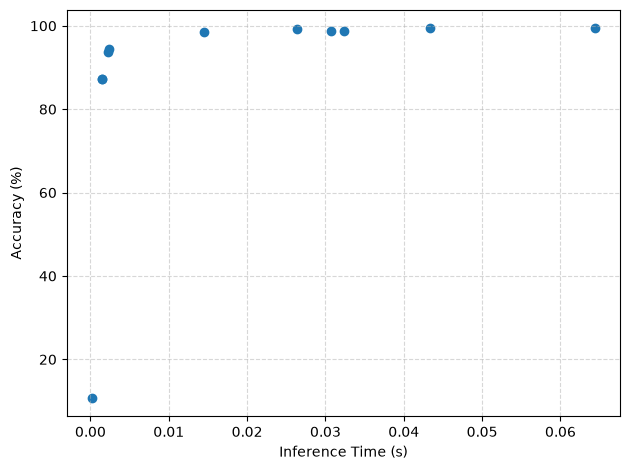

In [27]:
models_accuracy = [10.73, 93.75, 94.45, 98.83, 98.83, 99.36, 99.36, 98.61, 99.25, 87.13, 87.35]
models_inference_time = [0.00017, 0.00225, 0.00239, 0.03241, 0.03069, 0.06439, 0.04340, 0.01445, 0.02638, 0.00151, 0.00142]

plt.scatter(models_inference_time,models_accuracy)
plt.ylabel("Accuracy (%)")
plt.xlabel("Inference Time (s)")
plt.tight_layout()
plt.xticks()
plt.yticks()
plt.grid(linestyle = "--", alpha = 0.5)
plt.show()


## Choosing the best performing models and testing their accuracy on new dataset

In [29]:
# Including only the best performing models which means that only optimized models are being tested on writer-dependent dataset
y_pred_wdt_tree = clf_tree_f.predict(X_wdt)
y_pred_wdt_rf = clf_rf_f.predict(X_wdt)
y_pred_wdt_svm = pipe_svm_f.predict(X_wdt) 
y_pred_wdt_knn  = pipe_knn_f.predict(X_wdt)
y_pred_wdt_gnb = clf_gnb_f.predict(X_wdt)

# Calculating accuracy for each model separately
acc_tree = accuracy_score(y_wdt, y_pred_wdt_tree)
acc_rf   = accuracy_score(y_wdt, y_pred_wdt_rf)
acc_svm = accuracy_score(y_wdt, y_pred_wdt_svm)
acc_knn  = accuracy_score(y_wdt, y_pred_wdt_knn)
acc_gnb = accuracy_score(y_wdt, y_pred_wdt_gnb)


print("Accuracy on writer-dependent dataset:")
print(f"- Accuracy of Decision Tree model:          {acc_tree:.4f}")
print(f"- Accuracy of Random Forest model:          {acc_rf:.4f}")
print(f"- Accuracy of Support Vector Machine model: {acc_svm:.4f}")
print(f"- Accuracy of KNN Classifier model:         {acc_knn:.4f}")
print(f"- Accuracy of Gaussian Naive Bayes model:   {acc_gnb:.4f}")

Accuracy on writer-dependent dataset:
- Accuracy of Decision Tree model:          0.9455
- Accuracy of Random Forest model:          0.9888
- Accuracy of Support Vector Machine model: 0.9973
- Accuracy of KNN Classifier model:         0.9936
- Accuracy of Gaussian Naive Bayes model:   0.8895


Complex models such as Support Vector Machine (99.73%), KNN (99.36%), and Random Forest (98.88%) achieve almost perfect accuracy on the writer-dependent dataset outperforming simpler classifiers like Gaussian Naive Bayes (88.95%). While these results demonstrate excellent adaptation to known handwriting styles, they also suggest a potential risk of overfitting. Evaluating these models on the final, independent test dataset is necessary to determine if the increased complexity provides a advantage on unseen data.

## Evaluating models on test dataset

In [31]:
# Testing the best performing optimized models on the final test dataset
y_pred_test_tree = clf_tree_f.predict(X_test)
y_pred_test_rf = clf_rf_f.predict(X_test)
y_pred_test_svm = pipe_svm_f.predict(X_test) 
y_pred_test_knn  = pipe_knn_f.predict(X_test)
y_pred_test_gnb = clf_gnb_f.predict(X_test)

# Calculating accuracy for each model separately
acc_test_tree = accuracy_score(y_test, y_pred_test_tree)
acc_test_rf   = accuracy_score(y_test, y_pred_test_rf)
acc_test_svm = accuracy_score(y_test, y_pred_test_svm)
acc_test_knn  = accuracy_score(y_test, y_pred_test_knn)
acc_test_gnb = accuracy_score(y_test, y_pred_test_gnb)


print("Accuracy on test dataset:")
print(f"- Accuracy of Decision Tree model:          {acc_test_tree:.4f}")
print(f"- Accuracy of Random Forest model:          {acc_test_rf:.4f}")
print(f"- Accuracy of Support Vector Machine model: {acc_test_svm:.4f}")
print(f"- Accuracy of KNN Classifier model:         {acc_test_knn:.4f}")
print(f"- Accuracy of Gaussian Naive Bayes model:   {acc_test_gnb:.4f}")

Accuracy on test dataset:
- Accuracy of Decision Tree model:          0.8919
- Accuracy of Random Forest model:          0.9614
- Accuracy of Support Vector Machine model: 0.9780
- Accuracy of KNN Classifier model:         0.9706
- Accuracy of Gaussian Naive Bayes model:   0.8193


We can see that decrease in accuracy on the independent test dataset occurred across all evaluated models. The Support Vector Machine maintained the highest performance with an accuracy of 97.80%, followed by the KNN Classifier at 97.06% and Random Forest at 96.14%. Simpler models achieved the lowest results, Decision Tree achieved 89.19% and Gaussian Naive Bayes scored 81.93%.

These results confirm that greater model complexity provides a significant advantage for this classification problem. Advanced algorithms demonstrate better generalization capabilities on handwriting samples from unknown authors. The accuracy difference between the writer-dependent and independent test datasets is low for complex models, where simpler classifiers experienced big performance drops. The increased computational cost of advanced models is fully justified by their accuracy when working with new, unseen datasets.

## Creating Confusion Matrix for best performing model on test dataset (Support Vector Machine)

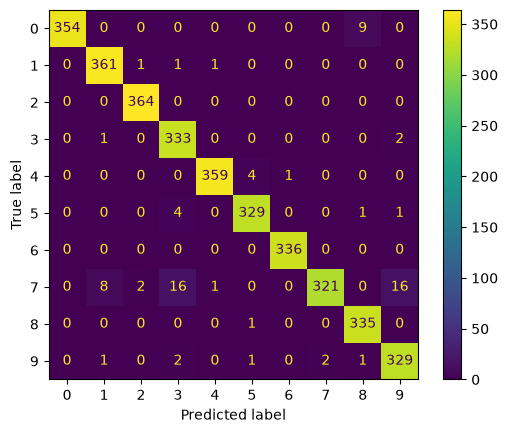

In [32]:
confusion_matrix = metrics.confusion_matrix(y_test,y_pred_test_svm)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix)
cm_display.plot()
plt.show()

### Sources I used while completing this task : 

* Physical Book "Hands-On Machine Learning with Scikit-Learn and TensorFlow"
* Python Documentation (including all libraries)
* https://github.com/AI-MED-AGH/AI_MED_Recruitment (The example part of that repo)
* https://www.datacamp.com/tutorial/decision-tree-classification-python?utm_cid=23781701478&utm_aid=196565213035&utm_campaign=260417_1-ps-dscia%7Eamx-tofu%7Epython_2-b2c_3-europe_4-prc_5-na_6-na_7-le_8-pdsh-go_9-nb-e_10-na_11-na&utm_loc=1011367-&utm_mtd=p-c&utm_kw=decision+tree+classification+python&utm_source=google&utm_medium=paid_search&utm_content=ps-dscia%7Eeurope-en%7Eamx%7Etofu%7Etutorial%7Epython&gad_source=1&gad_campaignid=23781701478&gbraid=0AAAAADQ9WsG_ygg5dzzWYWZ9UoZFgl7r7&gclid=Cj0KCQjwlsfWBhD4ARIsACL7p1Hkq1znJI8uXLamnCj6sjSiIhLZnbwSTb5UrzMD3K5A7lq7tWrj_S8aAivuEALw_wcB&dc_referrer=https%3A%2F%2Fwww.google.com%2F
* https://medium.com/biased-algorithms/grid-search-for-decision-tree-ababbfb89833
* https://medium.com/cloudvillains/random-forest-with-grid-search-b739fb0da311
* https://www.geeksforgeeks.org/machine-learning/support-vector-machine-algorithm/
* https://www.unite.ai/pl/a-quick-guide-to-knn-algorithm/
* https://www.flowhunt.io/pl/slownik/k-nearest-neighbors/
* https://www.datacamp.com/tutorial/what-is-a-confusion-matrix-in-machine-learning?utm_cid=19589720821&utm_aid=157156374951&utm_campaign=230119_1-ps-other~dsa-tofu~all_2-b2c_3-europe_4-prc_5-na_6-na_7-le_8-pdsh-go_9-nb-e_10-na_11-na&utm_loc=1011367-&utm_mtd=-c&utm_kw=&utm_source=google&utm_medium=paid_search&utm_content=ps-other~europe-en~dsa~tofu~tutorial~machine-learning&gad_source=1&gad_campaignid=19589720821&gbraid=0AAAAADQ9WsHNTSXKbhPqHJrIf_qODQeLt&gclid=Cj0KCQjwlsfWBhD4ARIsACL7p1GwPSm_LWTssk25YO71M7iszMdBLQfHGVJQ4p8Bnmmk5SN6GT5ma2YaAs85EALw_wcB
* https://www.statsoft.pl/textbook/stathome_stat.html?https%3A%2F%2Fwww.statsoft.pl%2Ftextbook%2Fstnaiveb.html
* AI model Gemini Pro to better understand some concepts. However code was not generated by AI, everything that I wrote here was previously backed up by researching about specific topic. The 3rd source was very helpful in terms of implementing all the models

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.